# Task 2 — Player Segment Classification models

Round 1 compares the original and combined datasets with initial classifiers. Round 2 tries LightGBM, CatBoost, and XGBoost on the **same stratified 80/20 split** and compares original versus combined within each family. The metric is macro F₁. Saved models are loaded on rerun; fitted preprocessing stays in each Pipeline.

## 1. Load the original saved dataset and validation split

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import f1_score, make_scorer, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index

SEED = set_seed()
TARGET, ID, DATA_NAME = "segment", "player_id", "eda_original_v1"
SCORE = make_scorer(f1_score, average="macro", zero_division=0)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid")

data_card_path = SRC / "task2" / "data" / "eda" / f"{DATA_NAME}.json"
data_card = json.loads(data_card_path.read_text(encoding="utf-8"))
def read_split(split):
    path = SRC / data_card["splits"][split]["path"]
    return pd.read_parquet(path) if data_card["format"] == "parquet" else pd.read_csv(path)
train_df, test_df = read_split("train"), read_split("test")
assert train_df.drop(columns=[TARGET]).columns.tolist() == test_df.columns.tolist()
assert train_df[ID].is_unique and test_df[ID].is_unique
assert train_df[TARGET].notna().all() and set(train_df[TARGET].unique()) == {0, 1, 2, 3}
print("Dataset:", DATA_NAME, "| Train:", len(train_df), "| Test:", len(test_df))

Dataset: eda_original_v1 | Train: 104000 | Test: 25889


In [2]:
feature_cols = test_df.columns.drop(ID).tolist()
X, y = train_df[feature_cols], train_df[TARGET].astype(int)
dev_idx, valid_idx = train_test_split(np.arange(len(y)), test_size=.20,
                                      stratify=y, random_state=SEED)
X_dev, X_valid = X.iloc[dev_idx], X.iloc[valid_idx]
y_dev, y_valid = y.iloc[dev_idx], y.iloc[valid_idx]
assert y_dev.index.intersection(y_valid.index).empty
display(pd.DataFrame({
    "development": y_dev.value_counts().sort_index(),
    "validation": y_valid.value_counts().sort_index(),
    "development_pct": y_dev.value_counts(normalize=True).sort_index().mul(100).round(2),
    "validation_pct": y_valid.value_counts(normalize=True).sort_index().mul(100).round(2),
}))

,development,validation,development_pct,validation_pct
segment,,,,
0,32747,8187,39.36,39.36
1,20827,5207,25.03,25.03
2,16811,4203,20.21,20.21
3,12815,3203,15.40,15.40


## 2. Preprocessing and artifact reuse

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

string_cols = X.select_dtypes(include="object").columns.tolist()
game_mode_col = ["preferred_game_mode"]  # Numeric code for a nominal mode.
numeric_cols = [c for c in feature_cols if c not in string_cols + game_mode_col]
noise_cols = ["random_metric_1", "random_metric_2", "random_metric_3"]
assert len(string_cols) == 10 and len(numeric_cols) == 33
assert set(noise_cols) <= set(numeric_cols)

def make_preprocessor(*, scale=False, drop_noise=False, dataset="original", drop_tiers=()):
    cols = numeric_cols if dataset == "original" else combined_numeric_cols
    selected_numeric = [c for c in cols if not (drop_noise and c in noise_cols)]
    selected_string = [c for c in string_cols if c not in drop_tiers]
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), selected_numeric),
        ("string", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="<missing>")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), selected_string),
        ("game_mode", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value=-1)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), game_mode_col),
    ], remainder="drop", sparse_threshold=0)

SAVE_DIR = SRC / "task2" / "save"
def model_paths(name):
    return SAVE_DIR / f"{name}.joblib", SAVE_DIR / f"{name}.json", SAVE_DIR / f"{name}-evaluation.json"

def load_model(name):
    model_path, card_path, _ = model_paths(name)
    card = json.loads(card_path.read_text(encoding="utf-8"))
    assert card["model_path"] == f"task2/save/{name}.joblib"
    return joblib.load(model_path)

def saved_result(name, *, dataset="original"):
    model_path, card_path, evaluation_path = model_paths(name)
    if not any(p.exists() for p in (model_path, card_path, evaluation_path)):
        return None
    if not model_path.exists() or not card_path.exists():
        raise RuntimeError(f"Incomplete model artifact for {name}")
    model_card = json.loads(card_path.read_text(encoding="utf-8"))
    expected_data_name = DATA_NAME if dataset == "original" else COMBINED_DATA_NAME
    valid_X = X_valid if dataset == "original" else X_valid_combined
    if model_card["data_name"] != expected_data_name:
        raise ValueError(f"{name} is linked to a different dataset")
    if not evaluation_path.exists():
        pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
        result = evaluate_model(task=2, name=name, y_true=y_valid, y_pred=pred,
                                card={"split": "stratified holdout 20%", "seed": SEED})
        print("Loaded model and recorded missing evaluation:", name)
        return result
    result = json.loads(evaluation_path.read_text(encoding="utf-8"))
    if result["metric"] != "macro_F1" or result["data_name"] != expected_data_name:
        raise ValueError(f"Inconsistent evaluation for {name}")
    print(f"Loaded {name}: macro F1 = {result['score']:.5f}")
    return result

def record_model(name, model, idea, tuning="none", *, dataset="original"):
    data_name = DATA_NAME if dataset == "original" else COMBINED_DATA_NAME
    valid_X = X_valid if dataset == "original" else X_valid_combined
    save_model(task=2, name=name, model=model, data_name=data_name,
               card={"idea": idea, "seed": SEED, "split": "stratified 80/20", "tuning": tuning})
    pred = np.asarray(model.predict(valid_X)).reshape(-1)
    result = evaluate_model(task=2, name=name, y_true=y_valid, y_pred=pred,
                            card={"split": "held-out validation 20%", "seed": SEED,
                                  "tuning": tuning})
    print(f"Trained {name}: macro F1 = {result['score']:.5f}")
    return result

## 3. Round 1 — initial classifiers

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

name = "t2_dummy_original_v1"
if saved_result(name) is None:
    model = DummyClassifier(strategy="most_frequent")
    model.fit(X_dev, y_dev)
    record_model(name, model, "Majority-class reference")

Loaded t2_dummy_original_v1: macro F1 = 0.14122


In [5]:
name = "t2_logreg_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(scale=True)),
        ("classifier", LogisticRegression(max_iter=800, class_weight="balanced",
                                          random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Imputation, one-hot encoding, scaling, balanced logistic regression")

Loaded t2_logreg_original_v1: macro F1 = 0.74376


In [6]:
name = "t2_rf_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=150, max_depth=18, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Random forest with imputed numeric and one-hot categorical inputs")

Loaded t2_rf_original_v1: macro F1 = 0.72933


In [7]:
name = "t2_hgb_original_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Histogram gradient boosting with all 44 provided features")

Loaded t2_hgb_original_v1: macro F1 = 0.74654


### Test the three documented noise columns

In [8]:
name = "t2_hgb_no_noise_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "Same HGB settings without three datacard-documented noise columns")

Loaded t2_hgb_no_noise_v1: macro F1 = 0.74944


### Small development-only search on the no-noise HGB

In [9]:
name = "t2_hgb_no_noise_tuned_v1"
if saved_result(name) is None:
    search = RandomizedSearchCV(
        estimator=Pipeline([
            ("preprocess", make_preprocessor(drop_noise=True)),
            ("classifier", HistGradientBoostingClassifier(
                early_stopping=True, random_state=SEED)),
        ]),
        param_distributions={
            "classifier__max_iter": [120, 200, 280],
            "classifier__learning_rate": [.04, .08, .12],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [20, 40, 80],
            "classifier__l2_regularization": [0., 1., 5.],
        },
        n_iter=4, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev, y_dev)
    print("Best development CV macro F1:", round(search.best_score_, 5))
    print("Best settings:", search.best_params_)
    record_model(name, search.best_estimator_, "Development CV search on no-noise HGB",
                 tuning={"cv": "3-fold stratified", "searches": 4,
                         "best_params": search.best_params_,
                         "best_cv_macro_F1": search.best_score_})

Loaded t2_hgb_no_noise_tuned_v1: macro F1 = 0.74555


### Add the combined feature dataset to the same holdout

The EDA notebook has already saved deterministic row-level features. Match IDs and labels before applying the original row indices.

In [10]:
COMBINED_DATA_NAME = "eda_combined_v1"
combined_card_path = SRC / "task2" / "data" / "eda" / f"{COMBINED_DATA_NAME}.json"
combined_card = json.loads(combined_card_path.read_text(encoding="utf-8"))
def read_combined_split(split):
    path = SRC / combined_card["splits"][split]["path"]
    return pd.read_parquet(path) if combined_card["format"] == "parquet" else pd.read_csv(path)
combined_train, combined_test = read_combined_split("train"), read_combined_split("test")
assert combined_train[ID].equals(train_df[ID])
assert combined_test[ID].equals(test_df[ID])
assert combined_train[TARGET].astype(int).equals(y)
combined_feature_cols = combined_test.columns.drop(ID).tolist()
engineered_cols = [c for c in combined_feature_cols if c not in feature_cols]
assert combined_feature_cols[:len(feature_cols)] == feature_cols
assert len(engineered_cols) == 14
assert combined_train[feature_cols].equals(train_df[feature_cols])
assert combined_test[feature_cols].equals(test_df[feature_cols])
combined_numeric_cols = numeric_cols + engineered_cols
X_dev_combined = combined_train.iloc[dev_idx][combined_feature_cols]
X_valid_combined = combined_train.iloc[valid_idx][combined_feature_cols]
assert X_valid_combined.index.equals(X_valid.index)
print("Same development/validation rows; original features:", len(feature_cols),
      "combined features:", len(combined_feature_cols))

Same development/validation rows; original features: 44 combined features: 58


### Matched classifiers on combined features

In [11]:
name = "t2_logreg_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(scale=True, dataset="combined")),
        ("classifier", LogisticRegression(max_iter=800, class_weight="balanced",
                                          random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "Balanced logistic regression with 14 behavior features",
                 dataset="combined")

Loaded t2_logreg_combined_v1: macro F1 = 0.74355


In [12]:
name = "t2_rf_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(dataset="combined")),
        ("classifier", RandomForestClassifier(
            n_estimators=150, max_depth=18, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "Random forest with 14 behavior features",
                 dataset="combined")

Loaded t2_rf_combined_v1: macro F1 = 0.72956


In [13]:
name = "t2_hgb_combined_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(dataset="combined")),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "HGB with raw and 14 behavior features",
                 dataset="combined")

Loaded t2_hgb_combined_v1: macro F1 = 0.74559


In [14]:
name = "t2_hgb_combined_no_noise_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, dataset="combined")),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "HGB with behavior features, without three noise columns",
                 dataset="combined")

Loaded t2_hgb_combined_no_noise_v1: macro F1 = 0.74808


In [15]:
name = "t2_hgb_combined_no_noise_tuned_v1"
if saved_result(name, dataset="combined") is None:
    search = RandomizedSearchCV(
        estimator=Pipeline([
            ("preprocess", make_preprocessor(drop_noise=True, dataset="combined")),
            ("classifier", HistGradientBoostingClassifier(
                early_stopping=True, random_state=SEED)),
        ]),
        param_distributions={
            "classifier__max_iter": [120, 200, 280],
            "classifier__learning_rate": [.04, .08, .12],
            "classifier__max_leaf_nodes": [15, 31, 63],
            "classifier__min_samples_leaf": [20, 40, 80],
            "classifier__l2_regularization": [0., 1., 5.],
        },
        n_iter=4, scoring=SCORE, cv=CV, refit=True,
        random_state=SEED, n_jobs=1,
    )
    search.fit(X_dev_combined, y_dev)
    print("Best development CV macro F1:", round(search.best_score_, 5))
    print("Best settings:", search.best_params_)
    record_model(name, search.best_estimator_, "Development CV search on combined no-noise HGB",
                 tuning={"cv": "3-fold stratified", "searches": 4,
                         "best_params": search.best_params_,
                         "best_cv_macro_F1": search.best_score_}, dataset="combined")

Loaded t2_hgb_combined_no_noise_tuned_v1: macro F1 = 0.74636


## 4. Rank original and combined models on the same Validation rows

,name,dataset,macro_F1,F1_casual,F1_grinder,F1_social,F1_whale
0,t2_hgb_no_noise_v1,eda_original_v1,0.7494,0.8207,0.7394,0.7133,0.7243
1,t2_hgb_combined_no_noise_v1,eda_combined_v1,0.7481,0.8195,0.7368,0.7137,0.7224
2,t2_hgb_original_v1,eda_original_v1,0.7465,0.8182,0.7368,0.7102,0.7210
3,t2_hgb_combined_no_noise_tuned_v1,eda_combined_v1,0.7464,0.8183,0.7376,0.7072,0.7224
4,t2_hgb_combined_v1,eda_combined_v1,0.7456,0.8180,0.7359,0.7093,0.7192
5,t2_hgb_no_noise_tuned_v1,eda_original_v1,0.7455,0.8200,0.7382,0.7065,0.7175
6,t2_logreg_original_v1,eda_original_v1,0.7438,0.7985,0.7375,0.7022,0.7369
7,t2_logreg_combined_v1,eda_combined_v1,0.7436,0.7984,0.7380,0.7013,0.7365
8,t2_rf_combined_v1,eda_combined_v1,0.7296,0.7970,0.7116,0.6979,0.7118
9,t2_rf_original_v1,eda_original_v1,0.7293,0.7964,0.7154,0.6917,0.7138


Best Round 1 model: t2_hgb_no_noise_v1


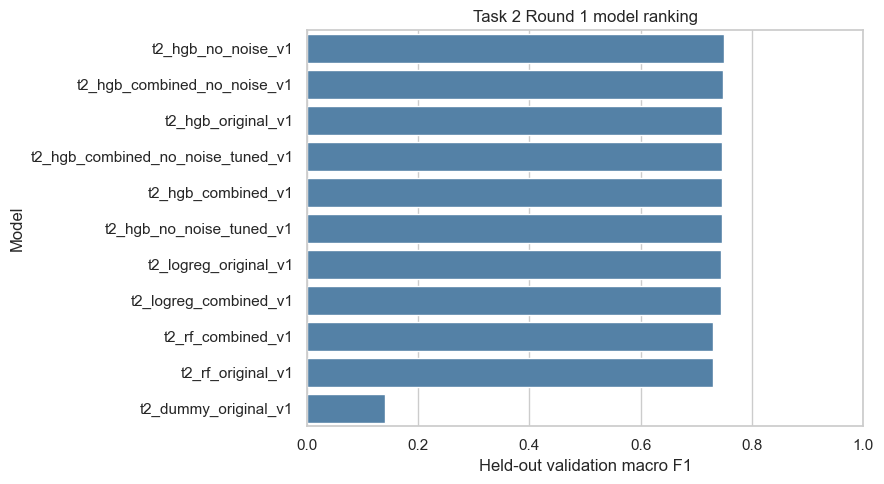

,configuration,original_F1,combined_F1,delta_combined_minus_original
0,logreg,0.74376,0.74355,-0.00020
1,rf,0.72933,0.72956,0.00023
2,hgb,0.74654,0.74559,-0.00095
3,hgb_no_noise,0.74944,0.74808,-0.00137
4,hgb_no_noise_tuned,0.74555,0.74636,0.00081


In [16]:
round1_names = [
    "t2_dummy_original_v1", "t2_logreg_original_v1",
    "t2_rf_original_v1", "t2_hgb_original_v1",
    "t2_hgb_no_noise_v1", "t2_hgb_no_noise_tuned_v1",
    "t2_logreg_combined_v1", "t2_rf_combined_v1",
    "t2_hgb_combined_v1", "t2_hgb_combined_no_noise_v1",
    "t2_hgb_combined_no_noise_tuned_v1",
]
index = read_evaluation_index(2)["evaluations"]
assert all(name in index for name in round1_names)
ranking_rows = []
for name in round1_names:
    data_name = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))["data_name"]
    valid_X = X_valid if data_name == DATA_NAME else X_valid_combined
    pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
    per_class = f1_score(y_valid, pred, labels=[0, 1, 2, 3], average=None,
                         zero_division=0)
    row = {"name": name, "dataset": data_name, "macro_F1": index[name]["score"]}
    row.update({f"F1_{label}": score for label, score in zip(
        ["casual", "grinder", "social", "whale"], per_class)})
    ranking_rows.append(row)
ranking = pd.DataFrame(ranking_rows).sort_values("macro_F1", ascending=False).reset_index(drop=True)
display(ranking.round(4))
print("Best Round 1 model:", ranking.iloc[0]["name"])
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ranking, x="macro_F1", y="name", color="steelblue", ax=ax)
ax.set(xlim=(0, 1), xlabel="Held-out validation macro F1", ylabel="Model",
       title="Task 2 Round 1 model ranking")
plt.tight_layout()
plt.show()
# Matched deltas isolate the added features for otherwise identical settings.
pairs = [
    ("logreg", "t2_logreg_original_v1", "t2_logreg_combined_v1"),
    ("rf", "t2_rf_original_v1", "t2_rf_combined_v1"),
    ("hgb", "t2_hgb_original_v1", "t2_hgb_combined_v1"),
    ("hgb_no_noise", "t2_hgb_no_noise_v1", "t2_hgb_combined_no_noise_v1"),
    ("hgb_no_noise_tuned", "t2_hgb_no_noise_tuned_v1", "t2_hgb_combined_no_noise_tuned_v1"),
]
comparison = pd.DataFrame([
    {"configuration": label, "original_F1": index[old]["score"],
     "combined_F1": index[new]["score"],
     "delta_combined_minus_original": index[new]["score"] - index[old]["score"]}
    for label, old, new in pairs
])
display(comparison.round(5))

## 5. Inspect the leading model

Winner: t2_hgb_no_noise_v1
              precision    recall  f1-score   support

      Casual     0.7888    0.8554    0.8207      8187
     Grinder     0.7437    0.7352    0.7394      5207
      Social     0.7386    0.6897    0.7133      4203
       Whale     0.7691    0.6844    0.7243      3203

    accuracy                         0.7655     20800
   macro avg     0.7601    0.7412    0.7494     20800
weighted avg     0.7643    0.7655    0.7638     20800



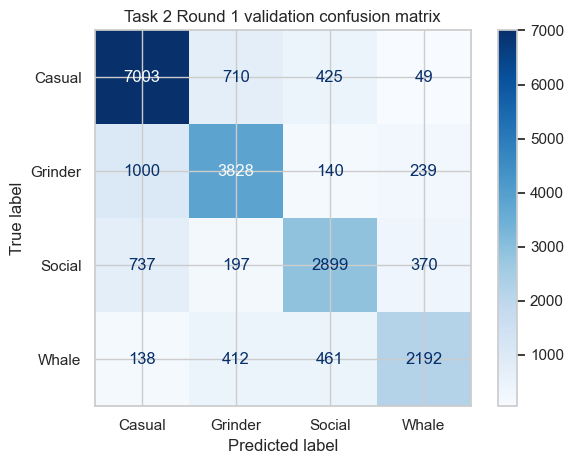

In [17]:
winner_name = ranking.iloc[0]["name"]
winner_model = load_model(winner_name)
winner_data_name = ranking.iloc[0]["dataset"]
X_winner_valid = X_valid if winner_data_name == DATA_NAME else X_valid_combined
winner_pred = np.asarray(winner_model.predict(X_winner_valid)).reshape(-1)
assert abs(f1_score(y_valid, winner_pred, average="macro") - ranking.iloc[0]["macro_F1"]) < 1e-12
print("Winner:", winner_name)
print(classification_report(y_valid, winner_pred,
                            target_names=["Casual", "Grinder", "Social", "Whale"],
                            digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_valid, winner_pred,
    display_labels=["Casual", "Grinder", "Social", "Whale"],
    cmap="Blues", values_format="d",
)
plt.title("Task 2 Round 1 validation confusion matrix")
plt.tight_layout()
plt.show()

Loaded permutation importance: t2_hgb_no_noise_v1


,feature,macro_F1_drop,std
0,loyalty_tier,0.2195,0.0035
1,engagement_level,0.0657,0.0056
2,vip_tier,0.0335,0.0036
3,days_since_last_login,0.0296,0.0014
4,total_playtime_hours,0.0267,0.0021
5,avg_monthly_spending,0.0250,0.0016
6,total_spending_thb,0.0206,0.0037
7,tournament_entries,0.0184,0.0025
8,chat_activity_score,0.0173,0.0034
9,friend_count,0.0171,0.0050


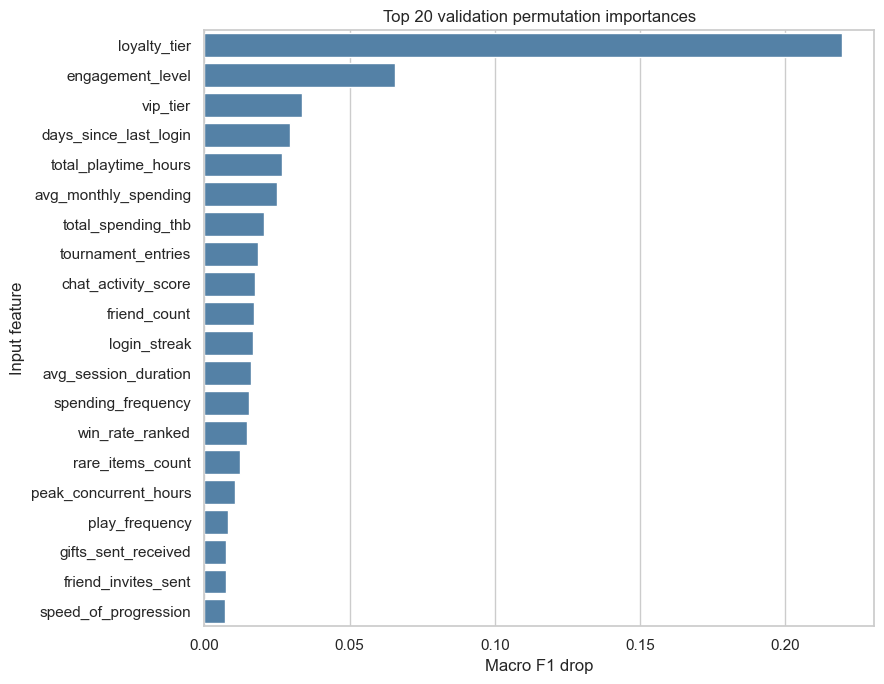

In [18]:
# Rank input columns, not one-hot output columns. Diagnostic only.
importance_path = SRC / "task2" / "models" / ".cache" / f"{winner_name}-permutation-v1.json"
model_path = model_paths(winner_name)[0]
cache_key = {"model_mtime_ns": model_path.stat().st_mtime_ns,
             "data_created_at": (data_card if winner_data_name == DATA_NAME else combined_card)["created_at"], "seed": SEED,
             "rows": 1500, "repeats": 2}
cached = json.loads(importance_path.read_text(encoding="utf-8")) if importance_path.exists() else None
if cached is not None and cached.get("key") == cache_key:
    feature_ranking = pd.DataFrame(cached["ranking"])
    print("Loaded permutation importance:", winner_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1500, random_state=SEED).to_numpy()
    winner_train = train_df if winner_data_name == DATA_NAME else combined_train
    winner_feature_cols = feature_cols if winner_data_name == DATA_NAME else combined_feature_cols
    sample_X = winner_train.iloc[sample_idx][winner_feature_cols]
    sample_y = y.iloc[sample_idx]
    permutation = permutation_importance(winner_model, sample_X, sample_y,
                                         scoring=SCORE, n_repeats=2,
                                         random_state=SEED, n_jobs=1)
    feature_ranking = pd.DataFrame({
        "feature": winner_feature_cols, "macro_F1_drop": permutation.importances_mean,
        "std": permutation.importances_std,
    }).sort_values("macro_F1_drop", ascending=False).reset_index(drop=True)
    importance_path.parent.mkdir(parents=True, exist_ok=True)
    importance_path.write_text(json.dumps({"key": cache_key,
                                           "ranking": feature_ranking.to_dict("records")}, indent=2),
                               encoding="utf-8")
    print("Computed permutation importance:", winner_name)
display(feature_ranking.round(4))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=feature_ranking.head(20), x="macro_F1_drop", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances",
       xlabel="Macro F1 drop", ylabel="Input feature")
plt.tight_layout()
plt.show()

### Round 1 findings

The tables above are generated from saved evaluation artifacts on the same held-out rows. Use the matched `comparison` table to judge each feature change; the overall ranking alone mixes model choices and feature choices. The winner report and permutation ranking are diagnostic. Confirm any small gains with repeated folds before treating them as stable. `engagement_level` and `loyalty_tier` remain temporal availability caveats.

## 6. Round 2 — boosted tree families

Keep the same development and validation rows and omit the three datacard-documented random columns. LightGBM uses ordinal-encoded categories with categorical splits, CatBoost uses the original string categories, and XGBoost uses the Round 1 one-hot preprocessing. These are family-specific baselines, not a tuned search. The matched original–combined comparison holds each family's settings fixed.

In [19]:
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import OrdinalEncoder

# The string categorical columns contain Python None, not np.nan. Replace it
# with an explicit category for CatBoost and LightGBM; fit on development only.
def make_native_preprocessor(*, dataset, family, drop_tiers=(), drop_features=()):
    assert dataset in {"original", "combined"}
    assert family in {"lightgbm", "catboost"}
    source_numeric = numeric_cols if dataset == "original" else combined_numeric_cols
    selected_numeric = [c for c in source_numeric if c not in noise_cols and c not in drop_features] + [
        c for c in game_mode_col if c not in drop_features]
    selected_string = [c for c in string_cols if c not in drop_tiers and c not in drop_features]
    categorical_imputer = SimpleImputer(missing_values=None, strategy="constant",
                                        fill_value="<missing>")
    if family == "lightgbm":
        categorical_steps = Pipeline([
            ("impute", categorical_imputer),
            ("encode", OrdinalEncoder(handle_unknown="use_encoded_value",
                                      unknown_value=-1)),
        ])
    else:
        categorical_steps = categorical_imputer
    return ColumnTransformer([
        ("categorical", categorical_steps, selected_string),
        ("numeric", SimpleImputer(strategy="median", add_indicator=True),
         selected_numeric),
    ], remainder="drop", sparse_threshold=0)

CAT_INDICES = list(range(len(string_cols)))
print("Native categorical columns:", string_cols)
print("Numerically coded game mode remains numeric for native learners.")

Native categorical columns: ['region', 'platform', 'device_type', 'payment_method', 'language', 'account_status', 'player_type_tag', 'engagement_level', 'loyalty_tier', 'skill_tier']
Numerically coded game mode remains numeric for native learners.


### LightGBM — original, then combined

In [20]:
name = "t2_lgb_original_no_noise_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="original", family="lightgbm")),
        ("classifier", LGBMClassifier(
            n_estimators=350, learning_rate=.05, num_leaves=31,
            min_child_samples=40, reg_lambda=1., verbosity=-1,
            random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev, y_dev, classifier__categorical_feature=CAT_INDICES)
    record_model(name, model, "LightGBM with native categorical splits and three noise columns removed")

Loaded t2_lgb_original_no_noise_v1: macro F1 = 0.74851


In [21]:
name = "t2_lgb_combined_no_noise_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="combined", family="lightgbm")),
        ("classifier", LGBMClassifier(
            n_estimators=350, learning_rate=.05, num_leaves=31,
            min_child_samples=40, reg_lambda=1., verbosity=-1,
            random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev_combined, y_dev, classifier__categorical_feature=CAT_INDICES)
    record_model(name, model, "LightGBM native categorical baseline plus 14 behavior features",
                 dataset="combined")

Loaded t2_lgb_combined_no_noise_v1: macro F1 = 0.74685


### CatBoost — original, then combined

In [22]:
name = "t2_cat_original_no_noise_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="original", family="catboost")),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=CAT_INDICES,
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "CatBoost native categorical baseline without three noise columns")

Loaded t2_cat_original_no_noise_v1: macro F1 = 0.75025


In [23]:
name = "t2_cat_combined_no_noise_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="combined", family="catboost")),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=CAT_INDICES,
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "CatBoost native categorical baseline plus 14 behavior features",
                 dataset="combined")

Loaded t2_cat_combined_no_noise_v1: macro F1 = 0.74923


### XGBoost — original, then combined

In [24]:
name = "t2_xgb_original_no_noise_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True)),
        ("classifier", XGBClassifier(
            n_estimators=350, max_depth=5, learning_rate=.05,
            min_child_weight=5, subsample=.9, colsample_bytree=.9,
            reg_lambda=2., objective="multi:softprob", eval_metric="mlogloss",
            tree_method="hist", random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "XGBoost with one-hot inputs and three noise columns removed")

Loaded t2_xgb_original_no_noise_v1: macro F1 = 0.74805


In [25]:
name = "t2_xgb_combined_no_noise_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, dataset="combined")),
        ("classifier", XGBClassifier(
            n_estimators=350, max_depth=5, learning_rate=.05,
            min_child_weight=5, subsample=.9, colsample_bytree=.9,
            reg_lambda=2., objective="multi:softprob", eval_metric="mlogloss",
            tree_method="hist", random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "XGBoost one-hot baseline plus 14 behavior features",
                 dataset="combined")

Loaded t2_xgb_combined_no_noise_v1: macro F1 = 0.74679


## 7. Rank Rounds 1–2 and compare feature effects

Only the explicit names tried in these two rounds enter the ranking. Paired deltas below compare original with combined within the same model family and settings.

,name,dataset,macro_F1,F1_casual,F1_grinder,F1_social,F1_whale
0,t2_cat_original_no_noise_v1,eda_original_v1,0.7503,0.8209,0.7408,0.7089,0.7304
1,t2_hgb_no_noise_v1,eda_original_v1,0.7494,0.8207,0.7394,0.7133,0.7243
2,t2_cat_combined_no_noise_v1,eda_combined_v1,0.7492,0.8212,0.7387,0.7112,0.7259
3,t2_lgb_original_no_noise_v1,eda_original_v1,0.7485,0.8183,0.7364,0.7130,0.7263
4,t2_hgb_combined_no_noise_v1,eda_combined_v1,0.7481,0.8195,0.7368,0.7137,0.7224
5,t2_xgb_original_no_noise_v1,eda_original_v1,0.7481,0.8183,0.7361,0.7140,0.7238
6,t2_lgb_combined_no_noise_v1,eda_combined_v1,0.7468,0.8170,0.7356,0.7114,0.7234
7,t2_xgb_combined_no_noise_v1,eda_combined_v1,0.7468,0.8172,0.7345,0.7120,0.7235
8,t2_hgb_original_v1,eda_original_v1,0.7465,0.8182,0.7368,0.7102,0.7210
9,t2_hgb_combined_no_noise_tuned_v1,eda_combined_v1,0.7464,0.8183,0.7376,0.7072,0.7224


Best after Round 2: t2_cat_original_no_noise_v1


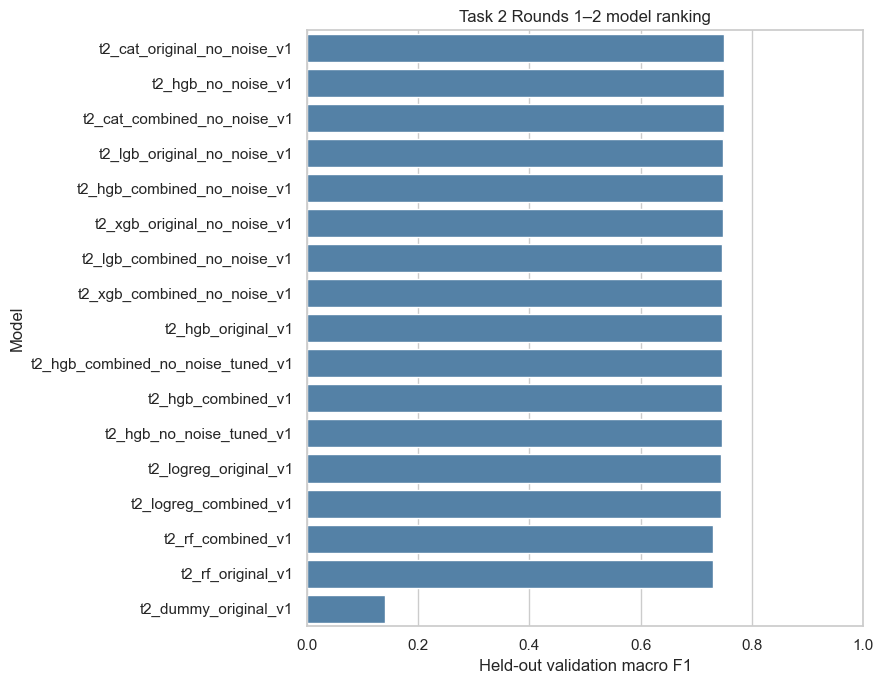

In [26]:
round2_model_names = [
    "t2_lgb_original_no_noise_v1", "t2_lgb_combined_no_noise_v1",
    "t2_cat_original_no_noise_v1", "t2_cat_combined_no_noise_v1",
    "t2_xgb_original_no_noise_v1", "t2_xgb_combined_no_noise_v1",
]
round2_names = round1_names + round2_model_names
index = read_evaluation_index(2)["evaluations"]
assert all(name in index and index[name]["metric"] == "macro_F1"
           for name in round2_names)
round2_rows = []
for name in round2_names:
    model_card = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))
    data_name = model_card["data_name"]
    valid_X = X_valid if data_name == DATA_NAME else X_valid_combined
    pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
    macro = f1_score(y_valid, pred, average="macro", zero_division=0)
    assert abs(macro - index[name]["score"]) < 1e-12
    per_class = f1_score(y_valid, pred, labels=[0, 1, 2, 3], average=None,
                         zero_division=0)
    row = {"name": name, "dataset": data_name, "macro_F1": macro}
    row.update({f"F1_{label}": score for label, score in zip(
        ["casual", "grinder", "social", "whale"], per_class)})
    round2_rows.append(row)
round2_ranking = pd.DataFrame(round2_rows).sort_values(
    "macro_F1", ascending=False).reset_index(drop=True)
display(round2_ranking.round(4))
print("Best after Round 2:", round2_ranking.iloc[0]["name"])
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=round2_ranking, x="macro_F1", y="name", color="steelblue", ax=ax)
ax.set(xlim=(0, 1), xlabel="Held-out validation macro F1", ylabel="Model",
       title="Task 2 Rounds 1–2 model ranking")
plt.tight_layout()
plt.show()

,family,original_F1,combined_F1,delta_combined_minus_original
0,HGB,0.74944,0.74808,-0.00137
1,LightGBM,0.74851,0.74685,-0.00166
2,CatBoost,0.75025,0.74923,-0.00102
3,XGBoost,0.74805,0.74679,-0.00126


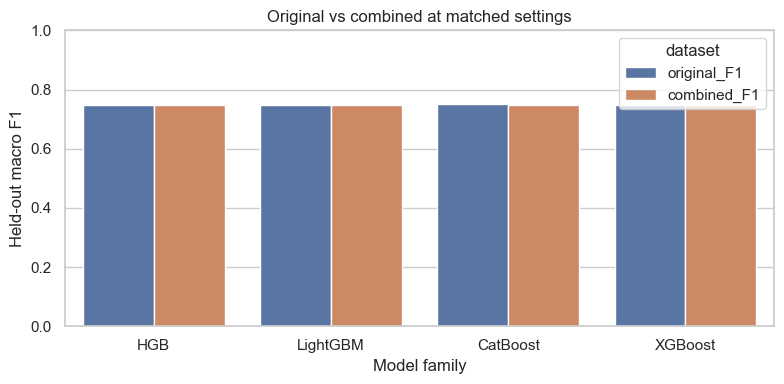

In [27]:
family_pairs = [
    ("HGB", "t2_hgb_no_noise_v1", "t2_hgb_combined_no_noise_v1"),
    ("LightGBM", "t2_lgb_original_no_noise_v1", "t2_lgb_combined_no_noise_v1"),
    ("CatBoost", "t2_cat_original_no_noise_v1", "t2_cat_combined_no_noise_v1"),
    ("XGBoost", "t2_xgb_original_no_noise_v1", "t2_xgb_combined_no_noise_v1"),
]
feature_effect = pd.DataFrame([
    {"family": family, "original_F1": index[old]["score"],
     "combined_F1": index[new]["score"],
     "delta_combined_minus_original": index[new]["score"] - index[old]["score"]}
    for family, old, new in family_pairs
])
display(feature_effect.round(5))
plot_scores = feature_effect.melt(id_vars="family",
                                  value_vars=["original_F1", "combined_F1"],
                                  var_name="dataset", value_name="macro_F1")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_scores, x="family", y="macro_F1", hue="dataset", ax=ax)
ax.set(ylim=(0, 1), xlabel="Model family", ylabel="Held-out macro F1",
       title="Original vs combined at matched settings")
plt.tight_layout()
plt.show()

### Round 2 interpretation

All four boosted-tree families have negative combined-minus-original deltas at matched settings (about **−0.0010 to −0.0017** macro F₁). The 14 engineered features therefore show no consistent benefit on this holdout. CatBoost on the original dataset is the current leader at **0.75025**, only **+0.00081** above the original HGB. CatBoost gains on Whale and Grinder relative to HGB but loses on Social. These small differences need paired multi-fold validation before choosing a final family. The availability time of `loyalty_tier` and `engagement_level` also remains unknown.

## 8. Inspect the Round 2 leader

Use the same report and permutation-importance format as Round 1. This is diagnostic analysis on the already-used holdout, not another tuning signal.

Winner: t2_cat_original_no_noise_v1
              precision    recall  f1-score   support

      Casual     0.7834    0.8622    0.8209      8187
     Grinder     0.7449    0.7367    0.7408      5207
      Social     0.7432    0.6776    0.7089      4203
       Whale     0.7820    0.6853    0.7304      3203

    accuracy                         0.7662     20800
   macro avg     0.7634    0.7405    0.7503     20800
weighted avg     0.7654    0.7662    0.7643     20800



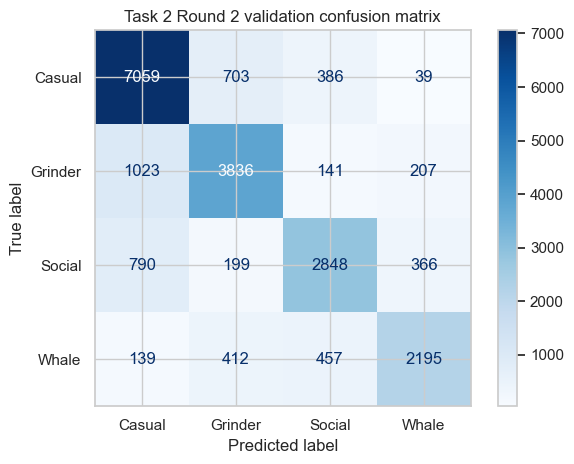

In [28]:
round2_winner_name = round2_ranking.iloc[0]["name"]
round2_winner_data_name = round2_ranking.iloc[0]["dataset"]
round2_winner_model = load_model(round2_winner_name)
round2_winner_X = X_valid if round2_winner_data_name == DATA_NAME else X_valid_combined
round2_winner_pred = np.asarray(round2_winner_model.predict(round2_winner_X)).reshape(-1)
print("Winner:", round2_winner_name)
print(classification_report(y_valid, round2_winner_pred,
                            target_names=["Casual", "Grinder", "Social", "Whale"],
                            digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_valid, round2_winner_pred,
    display_labels=["Casual", "Grinder", "Social", "Whale"],
    cmap="Blues", values_format="d",
)
plt.title("Task 2 Round 2 validation confusion matrix")
plt.tight_layout()
plt.show()

Loaded permutation importance: t2_cat_original_no_noise_v1


,feature,macro_F1_drop,std
0,loyalty_tier,0.2245,0.0060
1,engagement_level,0.0744,0.0054
2,vip_tier,0.0264,0.0023
3,avg_monthly_spending,0.0258,0.0039
4,days_since_last_login,0.0239,0.0002
5,total_playtime_hours,0.0229,0.0019
6,friend_count,0.0179,0.0041
7,chat_activity_score,0.0152,0.0002
8,total_spending_thb,0.0140,0.0044
9,avg_session_duration,0.0134,0.0013


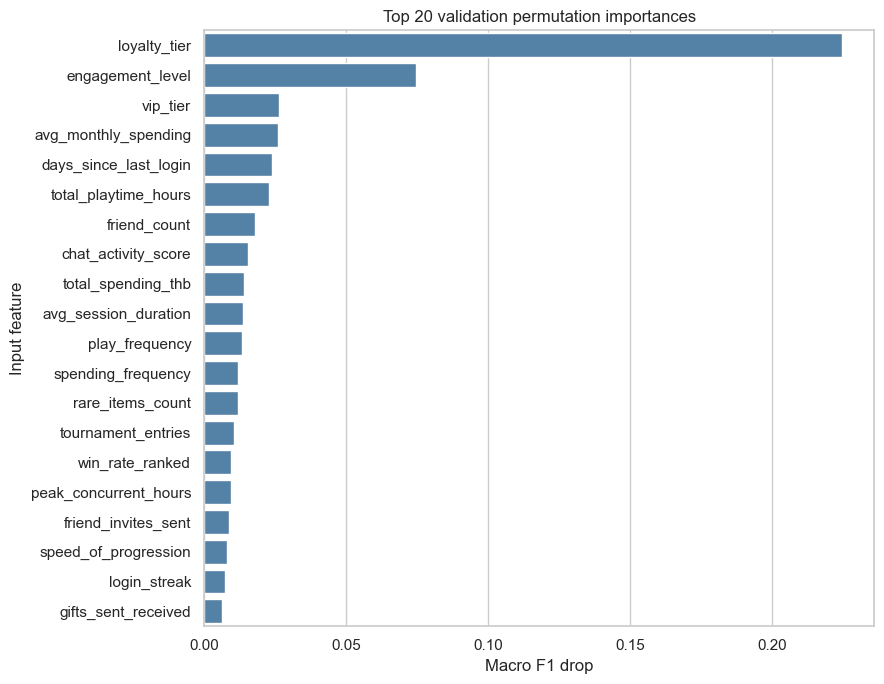

In [29]:
round2_importance_path = SRC / "task2" / "models" / ".cache" / f"{round2_winner_name}-permutation-v1.json"
round2_model_path = model_paths(round2_winner_name)[0]
round2_cache_key = {
    "model_mtime_ns": round2_model_path.stat().st_mtime_ns,
    "data_created_at": (data_card if round2_winner_data_name == DATA_NAME else combined_card)["created_at"],
    "seed": SEED, "rows": 1500, "repeats": 2,
}
round2_cached = json.loads(round2_importance_path.read_text(encoding="utf-8")) if round2_importance_path.exists() else None
if round2_cached is not None and round2_cached.get("key") == round2_cache_key:
    round2_feature_ranking = pd.DataFrame(round2_cached["ranking"])
    print("Loaded permutation importance:", round2_winner_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1500, random_state=SEED).to_numpy()
    winner_train = train_df if round2_winner_data_name == DATA_NAME else combined_train
    winner_feature_cols = feature_cols if round2_winner_data_name == DATA_NAME else combined_feature_cols
    sample_X = winner_train.iloc[sample_idx][winner_feature_cols]
    sample_y = y.iloc[sample_idx]
    permutation = permutation_importance(
        round2_winner_model, sample_X, sample_y, scoring=SCORE,
        n_repeats=2, random_state=SEED, n_jobs=1,
    )
    round2_feature_ranking = pd.DataFrame({
        "feature": winner_feature_cols,
        "macro_F1_drop": permutation.importances_mean,
        "std": permutation.importances_std,
    }).sort_values("macro_F1_drop", ascending=False).reset_index(drop=True)
    round2_importance_path.parent.mkdir(parents=True, exist_ok=True)
    round2_importance_path.write_text(
        json.dumps({"key": round2_cache_key,
                    "ranking": round2_feature_ranking.to_dict("records")}, indent=2),
        encoding="utf-8",
    )
    print("Computed permutation importance:", round2_winner_name)
display(round2_feature_ranking.round(4))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=round2_feature_ranking.head(20), x="macro_F1_drop", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances",
       xlabel="Macro F1 drop", ylabel="Input feature")
plt.tight_layout()
plt.show()

## 9. Tier ablation before multi-fold validation

The datacard describes `loyalty_tier` as spending-based and `engagement_level` as an engagement classification. Their creation time is unknown. Remove one at a time and both together from the two leading model families, always retaining the same split, hyperparameters, and noise-column removal. Then compare the no-tier original and combined datasets to see whether engineered behavior features compensate. No Test labels or external data are used.

In [30]:
TIER_COLS = ("loyalty_tier", "engagement_level")
assert set(TIER_COLS) <= set(string_cols)
print("Datacard: loyalty_tier is spending-based; engagement_level is a classified engagement tier.")
print("Their temporal availability is unknown. Other inferred tiers also need provenance review.")
display(pd.crosstab(train_df["loyalty_tier"].fillna("<missing>"),
                    train_df[TARGET], normalize="index").round(3))
display(pd.crosstab(train_df["engagement_level"].fillna("<missing>"),
                    train_df[TARGET], normalize="index").round(3))

Datacard: loyalty_tier is spending-based; engagement_level is a classified engagement tier.
Their temporal availability is unknown. Other inferred tiers also need provenance review.


segment,0,1,2,3
loyalty_tier,,,,
<missing>,0.396,0.247,0.210,0.148
Bronze,0.601,0.379,0.010,0.010
Diamond,0.010,0.010,0.568,0.412
Gold,0.232,0.155,0.343,0.270
Platinum,0.009,0.009,0.566,0.416
Silver,0.475,0.301,0.124,0.100


segment,0,1,2,3
engagement_level,,,,
<missing>,0.390,0.251,0.207,0.152
High,0.185,0.453,0.096,0.267
Low,0.575,0.080,0.291,0.053
Mid,0.393,0.247,0.203,0.157
Veteran,0.008,0.615,0.010,0.367


### HGB ablation — one tier at a time

In [31]:
name = "t2_hgb_no_loyalty_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, drop_tiers=("loyalty_tier",))),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "HGB baseline without noise columns or loyalty_tier")

Loaded t2_hgb_no_loyalty_v1: macro F1 = 0.64839


In [32]:
name = "t2_hgb_no_engagement_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, drop_tiers=("engagement_level",))),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "HGB baseline without noise columns or engagement_level")

Loaded t2_hgb_no_engagement_v1: macro F1 = 0.71125


### HGB ablation — both tiers, original then combined

In [33]:
name = "t2_hgb_no_tiers_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, drop_tiers=TIER_COLS)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "HGB without noise columns, loyalty_tier, or engagement_level")

Loaded t2_hgb_no_tiers_v1: macro F1 = 0.61262


In [34]:
name = "t2_hgb_combined_no_tiers_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True, dataset="combined",
                                         drop_tiers=TIER_COLS)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "HGB no-tier ablation plus 14 behavior features",
                 dataset="combined")

Loaded t2_hgb_combined_no_tiers_v1: macro F1 = 0.61259


### CatBoost ablation — one tier at a time

In [35]:
name = "t2_cat_no_loyalty_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="original", family="catboost",
                                                drop_tiers=("loyalty_tier",))),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=list(range(len(string_cols) - 1)),
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "CatBoost baseline without noise columns or loyalty_tier")

Loaded t2_cat_no_loyalty_v1: macro F1 = 0.65255


In [36]:
name = "t2_cat_no_engagement_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="original", family="catboost",
                                                drop_tiers=("engagement_level",))),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=list(range(len(string_cols) - 1)),
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "CatBoost baseline without noise columns or engagement_level")

Loaded t2_cat_no_engagement_v1: macro F1 = 0.71809


### CatBoost ablation — both tiers, original then combined

In [37]:
name = "t2_cat_no_tiers_v1"
if saved_result(name) is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="original", family="catboost",
                                                drop_tiers=TIER_COLS)),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=list(range(len(string_cols) - 2)),
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev, y_dev)
    record_model(name, model, "CatBoost without noise columns, loyalty_tier, or engagement_level")

Loaded t2_cat_no_tiers_v1: macro F1 = 0.62544


In [38]:
name = "t2_cat_combined_no_tiers_v1"
if saved_result(name, dataset="combined") is None:
    model = Pipeline([
        ("preprocess", make_native_preprocessor(dataset="combined", family="catboost",
                                                drop_tiers=TIER_COLS)),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass", cat_features=list(range(len(string_cols) - 2)),
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])
    model.fit(X_dev_combined, y_dev)
    record_model(name, model, "CatBoost no-tier ablation plus 14 behavior features",
                 dataset="combined")

Loaded t2_cat_combined_no_tiers_v1: macro F1 = 0.62212


## 10. Compare tier dependence and no-tier feature extraction

Rank only the named models from Rounds 1–3. The focused table below uses full-feature original baselines as reference and reports per-class F₁ so a macro change does not hide segment-specific damage.

In [39]:
ablation_names = [
    "t2_hgb_no_loyalty_v1", "t2_hgb_no_engagement_v1",
    "t2_hgb_no_tiers_v1", "t2_hgb_combined_no_tiers_v1",
    "t2_cat_no_loyalty_v1", "t2_cat_no_engagement_v1",
    "t2_cat_no_tiers_v1", "t2_cat_combined_no_tiers_v1",
]
round3_names = round2_names + ablation_names
index = read_evaluation_index(2)["evaluations"]
assert all(name in index and index[name]["metric"] == "macro_F1" for name in round3_names)
round3_rows = []
for name in round3_names:
    data_name = json.loads(model_paths(name)[1].read_text(encoding="utf-8"))["data_name"]
    valid_X = X_valid if data_name == DATA_NAME else X_valid_combined
    pred = np.asarray(load_model(name).predict(valid_X)).reshape(-1)
    macro = f1_score(y_valid, pred, average="macro", zero_division=0)
    assert abs(macro - index[name]["score"]) < 1e-12
    class_scores = f1_score(y_valid, pred, labels=[0, 1, 2, 3], average=None,
                            zero_division=0)
    row = {"name": name, "dataset": data_name, "macro_F1": macro}
    row.update({f"F1_{label}": score for label, score in zip(
        ["casual", "grinder", "social", "whale"], class_scores)})
    round3_rows.append(row)
round3_ranking = pd.DataFrame(round3_rows).sort_values(
    "macro_F1", ascending=False).reset_index(drop=True)
display(round3_ranking.round(4))
print("Best through Round 3:", round3_ranking.iloc[0]["name"])

,name,dataset,macro_F1,F1_casual,F1_grinder,F1_social,F1_whale
0,t2_cat_original_no_noise_v1,eda_original_v1,0.7503,0.8209,0.7408,0.7089,0.7304
1,t2_hgb_no_noise_v1,eda_original_v1,0.7494,0.8207,0.7394,0.7133,0.7243
2,t2_cat_combined_no_noise_v1,eda_combined_v1,0.7492,0.8212,0.7387,0.7112,0.7259
3,t2_lgb_original_no_noise_v1,eda_original_v1,0.7485,0.8183,0.7364,0.7130,0.7263
4,t2_hgb_combined_no_noise_v1,eda_combined_v1,0.7481,0.8195,0.7368,0.7137,0.7224
5,t2_xgb_original_no_noise_v1,eda_original_v1,0.7481,0.8183,0.7361,0.7140,0.7238
6,t2_lgb_combined_no_noise_v1,eda_combined_v1,0.7468,0.8170,0.7356,0.7114,0.7234
7,t2_xgb_combined_no_noise_v1,eda_combined_v1,0.7468,0.8172,0.7345,0.7120,0.7235
8,t2_hgb_original_v1,eda_original_v1,0.7465,0.8182,0.7368,0.7102,0.7210
9,t2_hgb_combined_no_noise_tuned_v1,eda_combined_v1,0.7464,0.8183,0.7376,0.7072,0.7224


Best through Round 3: t2_cat_original_no_noise_v1


,family,condition,name,macro_F1,delta_vs_full,F1_casual,F1_grinder,F1_social,F1_whale
0,HGB,full,t2_hgb_no_noise_v1,0.7494,0.0000,0.8207,0.7394,0.7133,0.7243
1,HGB,no loyalty,t2_hgb_no_loyalty_v1,0.6484,-0.1011,0.7546,0.6764,0.5146,0.6479
2,HGB,no engagement,t2_hgb_no_engagement_v1,0.7113,-0.0382,0.7955,0.6875,0.6759,0.6861
3,HGB,no tiers,t2_hgb_no_tiers_v1,0.6126,-0.1368,0.7363,0.6177,0.4758,0.6207
4,HGB,no tiers + combined,t2_hgb_combined_no_tiers_v1,0.6126,-0.1368,0.7325,0.6196,0.4749,0.6234
5,CatBoost,full,t2_cat_original_no_noise_v1,0.7503,0.0000,0.8209,0.7408,0.7089,0.7304
6,CatBoost,no loyalty,t2_cat_no_loyalty_v1,0.6526,-0.0977,0.7604,0.6777,0.5196,0.6525
7,CatBoost,no engagement,t2_cat_no_engagement_v1,0.7181,-0.0322,0.8005,0.6920,0.6823,0.6975
8,CatBoost,no tiers,t2_cat_no_tiers_v1,0.6254,-0.1248,0.7451,0.6284,0.4906,0.6376
9,CatBoost,no tiers + combined,t2_cat_combined_no_tiers_v1,0.6221,-0.1281,0.7430,0.6242,0.4887,0.6326


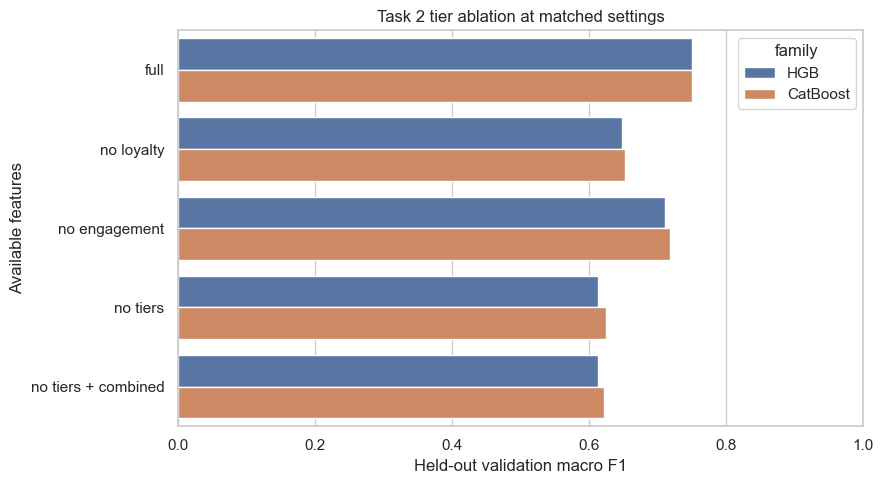

HGB no-tier combined minus original: -0.00003
CatBoost no-tier combined minus original: -0.00332


In [40]:
ablation_conditions = [
    ("HGB", "full", "t2_hgb_no_noise_v1"),
    ("HGB", "no loyalty", "t2_hgb_no_loyalty_v1"),
    ("HGB", "no engagement", "t2_hgb_no_engagement_v1"),
    ("HGB", "no tiers", "t2_hgb_no_tiers_v1"),
    ("HGB", "no tiers + combined", "t2_hgb_combined_no_tiers_v1"),
    ("CatBoost", "full", "t2_cat_original_no_noise_v1"),
    ("CatBoost", "no loyalty", "t2_cat_no_loyalty_v1"),
    ("CatBoost", "no engagement", "t2_cat_no_engagement_v1"),
    ("CatBoost", "no tiers", "t2_cat_no_tiers_v1"),
    ("CatBoost", "no tiers + combined", "t2_cat_combined_no_tiers_v1"),
]
focused_rows = []
for family, condition, name in ablation_conditions:
    row = round3_ranking.loc[round3_ranking.name == name].iloc[0]
    baseline = "t2_hgb_no_noise_v1" if family == "HGB" else "t2_cat_original_no_noise_v1"
    focused_rows.append({
        "family": family, "condition": condition, "name": name,
        "macro_F1": row.macro_F1,
        "delta_vs_full": row.macro_F1 - index[baseline]["score"],
        "F1_casual": row.F1_casual, "F1_grinder": row.F1_grinder,
        "F1_social": row.F1_social, "F1_whale": row.F1_whale,
    })
ablation_table = pd.DataFrame(focused_rows)
display(ablation_table.round(4))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=ablation_table, x="macro_F1", y="condition", hue="family", ax=ax)
ax.set(xlim=(0, 1), xlabel="Held-out validation macro F1", ylabel="Available features",
       title="Task 2 tier ablation at matched settings")
plt.tight_layout()
plt.show()
for family in ["HGB", "CatBoost"]:
    original = ablation_table.query("family == @family and condition == 'no tiers'").iloc[0]
    combined = ablation_table.query("family == @family and condition == 'no tiers + combined'").iloc[0]
    print(f"{family} no-tier combined minus original: {combined.macro_F1 - original.macro_F1:+.5f}")

### Interpretation and next experiment

Removing `loyalty_tier` causes the larger drop in both families; removing both tiers causes a still larger drop. Combined features do not recover the no-tier score. A large drop is evidence of predictive reliance, **not proof of leakage**; only feature provenance can establish availability at prediction time. The no-tier importance below identifies which remaining inputs carry the model. Defer paired k-fold comparison until the allowed feature set is decided.

## 11. What carries the no-tier model?

Inspect permutation importance of the best original no-tier model on the same validation sample. Treat this as a diagnostic, because correlated features can substitute for each other.

Loaded permutation importance: t2_cat_no_tiers_v1


,feature,macro_F1_drop,std
0,vip_tier,0.0741,0.0023
1,spending_frequency,0.0495,0.0022
2,avg_monthly_spending,0.0443,0.0021
3,days_since_last_login,0.0345,0.0059
4,total_spending_thb,0.0319,0.0039
5,rare_items_count,0.0315,0.0043
6,win_rate_ranked,0.0148,0.0008
7,speed_of_progression,0.0140,0.0007
8,total_playtime_hours,0.0140,0.0056
9,chat_activity_score,0.0115,0.0049


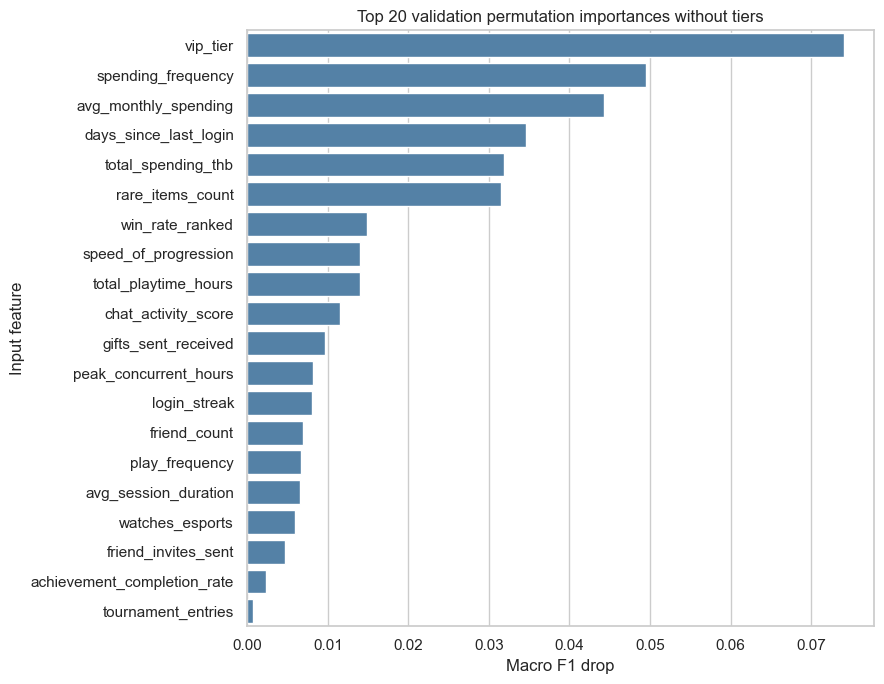

In [41]:
no_tier_name = ablation_table.query("condition == 'no tiers'").sort_values(
    "macro_F1", ascending=False).iloc[0]["name"]
no_tier_model = load_model(no_tier_name)
no_tier_importance_path = SRC / "task2" / "models" / ".cache" / f"{no_tier_name}-permutation-v1.json"
no_tier_model_path = model_paths(no_tier_name)[0]
no_tier_cache_key = {
    "model_mtime_ns": no_tier_model_path.stat().st_mtime_ns,
    "data_created_at": data_card["created_at"], "seed": SEED,
    "rows": 1500, "repeats": 2,
}
no_tier_cached = json.loads(no_tier_importance_path.read_text(encoding="utf-8")) if no_tier_importance_path.exists() else None
if no_tier_cached is not None and no_tier_cached.get("key") == no_tier_cache_key:
    no_tier_feature_ranking = pd.DataFrame(no_tier_cached["ranking"])
    print("Loaded permutation importance:", no_tier_name)
else:
    sample_idx = pd.Series(valid_idx).sample(n=1500, random_state=SEED).to_numpy()
    sample_X = train_df.iloc[sample_idx][feature_cols]
    sample_y = y.iloc[sample_idx]
    permutation = permutation_importance(no_tier_model, sample_X, sample_y,
                                         scoring=SCORE, n_repeats=2,
                                         random_state=SEED, n_jobs=1)
    no_tier_feature_ranking = pd.DataFrame({
        "feature": feature_cols, "macro_F1_drop": permutation.importances_mean,
        "std": permutation.importances_std,
    }).sort_values("macro_F1_drop", ascending=False).reset_index(drop=True)
    no_tier_importance_path.parent.mkdir(parents=True, exist_ok=True)
    no_tier_importance_path.write_text(
        json.dumps({"key": no_tier_cache_key,
                    "ranking": no_tier_feature_ranking.to_dict("records")}, indent=2),
        encoding="utf-8",
    )
    print("Computed permutation importance:", no_tier_name)
display(no_tier_feature_ranking.round(4))
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=no_tier_feature_ranking.head(20), x="macro_F1_drop", y="feature",
            color="steelblue", ax=ax)
ax.set(title="Top 20 validation permutation importances without tiers",
       xlabel="Macro F1 drop", ylabel="Input feature")
plt.tight_layout()
plt.show()

### Round 3 findings

- `loyalty_tier` carries the larger effect: removing it lowers HGB/CatBoost macro F₁ to **0.64839/0.65255**. Removing `engagement_level` lowers them to **0.71125/0.71809**.
- Removing both lowers them to **0.61262/0.62544**. Combined features do not recover the loss (**0.61259/0.62212**).
- The no-tier CatBoost relies most on `vip_tier`, purchase frequency, monthly spending, login recency, and total spending. `vip_tier` also needs an availability audit.
- A large ablation drop establishes reliance, not leakage. Confirm tier provenance before choosing the allowed feature set, then run paired stratified folds on the shortlisted configurations. Do not use this holdout for another broad feature search.

## 12. Round 4 — provenance boundary, paired folds, and fold-local pruning

**Competition scope:** The provided datacard defines `loyalty_tier` as spending-based, `engagement_level` as an engagement classification, and `vip_tier` as the current VIP level. The data description says Test has the same feature structure as Train, and the rules permit competition-provided data. No supplied file explains tier formulas, timestamps, or whether they predate a real-world prediction cutoff. Thus these fields are available as competition inputs, while operational leakage remains unresolved. This round evaluates the competition feature set and does not claim deployment safety.

Use **five paired stratified folds on development only**. Compare the original full CatBoost and HGB settings with CatBoost pruning eight low-importance raw inputs. On each fold, derive the prune list only from CatBoost trained on that fold's training portion, then refit on that same portion and score the untouched fold. Protect the three tier columns from pruning in this competition-scope check. The JSON result checkpoints each completed fold for reruns; CV fold fits are temporary analysis models and are not entered into the holdout `evaluation_index.json`.

In [42]:
from collections import Counter
from hashlib import sha256

TIERS_FOR_AUDIT = ("loyalty_tier", "engagement_level", "vip_tier")
assert set(TIERS_FOR_AUDIT) <= set(train_df.columns)
print("Provided datacard: loyalty_tier = spending-based tier; engagement_level = engagement classification;")
print("vip_tier = current VIP level. No generation formula or timestamp is supplied.")
print("Competition experiment uses the provided Train columns; operational availability is unresolved.")

def round4_catboost(*, drop_features=()):
    selected_categorical = [c for c in string_cols if c not in drop_features]
    return Pipeline([
        ("preprocess", make_native_preprocessor(
            dataset="original", family="catboost", drop_features=drop_features)),
        ("classifier", CatBoostClassifier(
            iterations=400, depth=6, learning_rate=.05, l2_leaf_reg=3.,
            loss_function="MultiClass",
            cat_features=list(range(len(selected_categorical))),
            verbose=False, allow_writing_files=False,
            thread_count=4, random_seed=SEED)),
    ])

def round4_hgb():
    return Pipeline([
        ("preprocess", make_preprocessor(drop_noise=True)),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=180, learning_rate=.08, max_leaf_nodes=31,
            min_samples_leaf=40, early_stopping=True, random_state=SEED)),
    ])

def fold_scores(model, features, labels):
    pred = np.asarray(model.predict(features)).reshape(-1)
    per_class = f1_score(labels, pred, labels=[0, 1, 2, 3],
                         average=None, zero_division=0)
    return {"macro_F1": float(f1_score(labels, pred, average="macro", zero_division=0)),
            **{f"F1_{label}": float(score) for label, score in zip(
                ["casual", "grinder", "social", "whale"], per_class)}}

def fold_prune_list(fitted_cat, count=8):
    # Aggregate numeric missing indicators back to their raw input column.
    feature_names = fitted_cat.named_steps["preprocess"].get_feature_names_out()
    importance = fitted_cat.named_steps["classifier"].feature_importances_
    raw_importance = {c: 0. for c in feature_cols if c not in noise_cols}
    for feature_name, value in zip(feature_names, importance):
        raw_name = feature_name.split("__", 1)[1].strip()
        if raw_name.startswith("missingindicator_"):
            raw_name = raw_name.removeprefix("missingindicator_")
        raw_importance[raw_name] += float(value)
    candidates = [c for c in raw_importance if c not in TIERS_FOR_AUDIT]
    return sorted(candidates, key=lambda c: (raw_importance[c], c))[:count]

# Check the selection logic on the already fitted development-only CatBoost.
example_pruned = fold_prune_list(load_model("t2_cat_original_no_noise_v1"))
assert len(example_pruned) == 8 and not set(example_pruned).intersection(TIERS_FOR_AUDIT)
print("Example prune list (diagnostic only; folds select their own):", example_pruned)

Provided datacard: loyalty_tier = spending-based tier; engagement_level = engagement classification;
vip_tier = current VIP level. No generation formula or timestamp is supplied.
Competition experiment uses the provided Train columns; operational availability is unresolved.
Example prune list (diagnostic only; folds select their own): ['account_status', 'platform', 'region', 'responds_to_discounts', 'skill_tier', 'language', 'player_type_tag', 'payment_method']


### Fit five paired development folds

In [43]:
cv_path = SRC / "task2" / "models" / "round4_cv_v1.json"
split_signature = sha256(
    np.asarray(dev_idx, dtype=np.int64).tobytes()
    + np.asarray(y_dev, dtype=np.int8).tobytes()
).hexdigest()
cv_config = {
    "data_name": DATA_NAME, "data_created_at": data_card["created_at"],
    "seed": SEED, "folds": 5, "prune_count": 8,
    "split": "stratified 80% development; 20% holdout excluded from CV",
    "split_signature": split_signature,
    "catboost": {"iterations": 400, "depth": 6, "learning_rate": .05,
                 "l2_leaf_reg": 3., "loss_function": "MultiClass"},
    "hgb": {"max_iter": 180, "learning_rate": .08, "max_leaf_nodes": 31,
            "min_samples_leaf": 40, "early_stopping": True},
}
if cv_path.exists():
    cv_result = json.loads(cv_path.read_text(encoding="utf-8"))
    assert cv_result["config"] == cv_config, "CV config changed; use a new result name"
    print("Loaded existing CV results:", len(cv_result["folds"]), "folds")
else:
    cv_result = {
        "card": "Five paired development folds: original CatBoost and HGB, plus fold-local CatBoost pruning. Validation holdout and Test excluded.",
        "config": cv_config, "folds": [],
    }

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (train_pos, check_pos) in enumerate(cv5.split(X_dev, y_dev), start=1):
    if any(saved["fold"] == fold for saved in cv_result["folds"]):
        print("Loaded fold", fold)
        continue
    fold_X_train, fold_X_check = X_dev.iloc[train_pos], X_dev.iloc[check_pos]
    fold_y_train, fold_y_check = y_dev.iloc[train_pos], y_dev.iloc[check_pos]
    assert fold_X_train.index.intersection(fold_X_check.index).empty

    full_cat = round4_catboost()
    full_cat.fit(fold_X_train, fold_y_train)
    cat_full_scores = fold_scores(full_cat, fold_X_check, fold_y_check)

    pruned_columns = fold_prune_list(full_cat, count=cv_config["prune_count"])
    assert not set(pruned_columns).intersection(TIERS_FOR_AUDIT)
    pruned_cat = round4_catboost(drop_features=pruned_columns)
    pruned_cat.fit(fold_X_train, fold_y_train)
    cat_pruned_scores = fold_scores(pruned_cat, fold_X_check, fold_y_check)

    hgb = round4_hgb()
    hgb.fit(fold_X_train, fold_y_train)
    hgb_scores = fold_scores(hgb, fold_X_check, fold_y_check)

    cv_result["folds"].append({
        "fold": fold, "train_rows": len(train_pos), "validation_rows": len(check_pos),
        "pruned_columns": pruned_columns,
        "cat_full": cat_full_scores, "cat_pruned": cat_pruned_scores,
        "hgb_full": hgb_scores,
    })
    cv_path.write_text(json.dumps(cv_result, indent=2) + "\n", encoding="utf-8")
    print(f"Fold {fold}: Cat {cat_full_scores['macro_F1']:.5f}, "
          f"pruned Cat {cat_pruned_scores['macro_F1']:.5f}, "
          f"HGB {hgb_scores['macro_F1']:.5f}; pruned {pruned_columns}")

assert len(cv_result["folds"]) == 5
print("Saved paired CV results:", cv_path)

Loaded existing CV results: 5 folds
Loaded fold 1
Loaded fold 2
Loaded fold 3
Loaded fold 4
Loaded fold 5
Saved paired CV results: C:\Users\BTCOM\Desktop\ml-final\src\task2\models\round4_cv_v1.json


### Compare scores and prune stability

,fold,model,macro_F1,F1_casual,F1_grinder,F1_social,F1_whale
0,1,cat_full,0.7497,0.8221,0.7380,0.7123,0.7266
1,1,cat_pruned,0.7500,0.8229,0.7384,0.7141,0.7245
2,1,hgb_full,0.7450,0.8171,0.7340,0.7115,0.7176
3,2,cat_full,0.7510,0.8193,0.7316,0.7130,0.7401
4,2,cat_pruned,0.7506,0.8191,0.7318,0.7097,0.7417
5,2,hgb_full,0.7446,0.8136,0.7248,0.7098,0.7302
6,3,cat_full,0.7531,0.8219,0.7432,0.7109,0.7362
7,3,cat_pruned,0.7524,0.8218,0.7432,0.7098,0.7348
8,3,hgb_full,0.7484,0.8182,0.7360,0.7089,0.7303
9,4,cat_full,0.7511,0.8246,0.7461,0.7103,0.7234


,macro_F1_mean,macro_F1_std,social_F1_mean,whale_F1_mean
model,,,,
cat_full,0.75012,0.00273,0.70924,0.73092
cat_pruned,0.74999,0.00248,0.70825,0.73152
hgb_full,0.74461,0.00286,0.70612,0.72133


model,cat_full,cat_pruned,hgb_full,cat_pruned_minus_full,cat_full_minus_hgb
fold,,,,,
1,0.74973,0.74996,0.74504,0.00023,0.00469
2,0.75098,0.75059,0.74461,-0.00039,0.00637
3,0.75306,0.75240,0.74836,-0.00066,0.00470
4,0.75111,0.75115,0.74474,0.00004,0.00637
5,0.74572,0.74585,0.74031,0.00013,0.00542


Mean pruned-minus-full CatBoost: -0.00013
Folds improved by pruning: 3 / 5


,feature,folds_pruned
0,device_type,5
1,language,5
2,account_status,5
3,platform,4
4,player_type_tag,4
5,skill_tier,4
6,payment_method,4
7,preferred_game_mode,3
8,responds_to_discounts,3
9,region,2


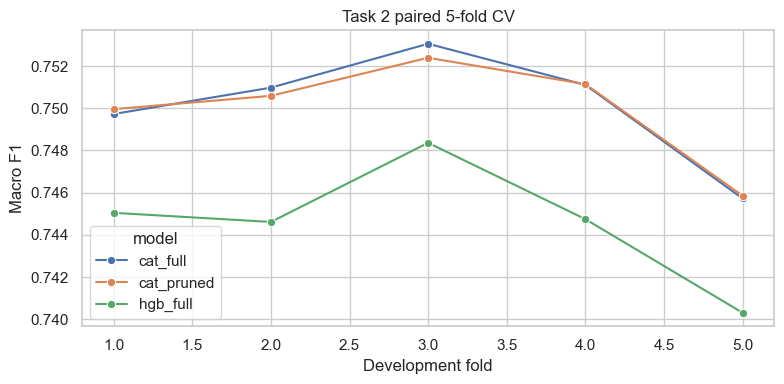

In [44]:
cv_rows = []
for result in cv_result["folds"]:
    for model_key in ["cat_full", "cat_pruned", "hgb_full"]:
        cv_rows.append({"fold": result["fold"], "model": model_key,
                        **result[model_key]})
cv_scores = pd.DataFrame(cv_rows).sort_values(["fold", "model"]).reset_index(drop=True)
display(cv_scores.round(4))
cv_summary = cv_scores.groupby("model").agg(
    macro_F1_mean=("macro_F1", "mean"),
    macro_F1_std=("macro_F1", "std"),
    social_F1_mean=("F1_social", "mean"),
    whale_F1_mean=("F1_whale", "mean"),
).sort_values("macro_F1_mean", ascending=False)
display(cv_summary.round(5))
paired = cv_scores.pivot(index="fold", columns="model", values="macro_F1")
paired["cat_pruned_minus_full"] = paired["cat_pruned"] - paired["cat_full"]
paired["cat_full_minus_hgb"] = paired["cat_full"] - paired["hgb_full"]
display(paired.round(5))
print("Mean pruned-minus-full CatBoost:", round(paired["cat_pruned_minus_full"].mean(), 5))
print("Folds improved by pruning:", int((paired["cat_pruned_minus_full"] > 0).sum()), "/ 5")
prune_counts = pd.DataFrame(Counter(
    feature for result in cv_result["folds"] for feature in result["pruned_columns"]
).most_common(), columns=["feature", "folds_pruned"])
display(prune_counts)
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=cv_scores, x="fold", y="macro_F1", hue="model", marker="o", ax=ax)
ax.set(xlabel="Development fold", ylabel="Macro F1", title="Task 2 paired 5-fold CV")
plt.tight_layout()
plt.show()

### Round 4 findings

- Full CatBoost: **0.75012 ± 0.00273** macro F₁ across five development folds; full HGB: **0.74461 ± 0.00286**. CatBoost wins on all five paired folds, with mean advantage **+0.00551**.
- Fold-local pruning of eight low-importance raw inputs gives CatBoost **0.74999 ± 0.00248**. It wins on three folds but loses **0.00013** on average; the gains are smaller than the losses. Keep the full CatBoost as the competition feature-set leader.
- The most frequently pruned inputs are low-use categorical columns such as `device_type`, `language`, `player_type_tag`, and `account_status`. The exact eight vary by fold; pruning is a possible simplification, not a demonstrated accuracy improvement.
- The supplied data does not reveal the generation time or formulas for `loyalty_tier`, `engagement_level`, or `vip_tier`. These CV results do not resolve operational leakage. Confirm provenance before deployment or build a separate no-tier model if those fields are unavailable at the prediction cutoff.